# Phase 3: Temperature-activated hopping

Between landings, surface atoms try to hop sideways. A hop succeeds with probability exp(-E/kT), where E = n x E_bond and n (0, 1 or 2) is the number of side neighbours at the atom's height. Isolated atoms move easily. Atoms sitting against a step or in a groove are held more strongly.

The model has two parameters:
* **epsilon = E_bond / kT** is the single *mobility parameter* for the dimensionless model (larger means stickier, i.e. colder).
* **hops** is the number of hop attempts per landed atom. It plays the role of deposition rate: slower deposition leaves more hops between arrivals.

Real units map onto these two numbers through the Arrhenius law, hops = nu0 * exp(-E_diff/kT) / F (see `units.py`).

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML

In [2]:
from dataclasses import asdict
from thin_film import thermal as th
from thin_film.units import thermal_parameters
from thin_film.plotting import plot_sweep, plot_surface
base = th.ThermalSettings()
base

ThermalSettings(n_columns=200, n_monolayers=50, n_runs=8, n_points=20, temperature=350.0, flux=1.0, e_bond=0.2, e_diff=0.8, nu0=10000000000000.0, max_hops=10000.0, seed=42)

## 1. Dimensionless model: vary only epsilon (100 hops per landing)

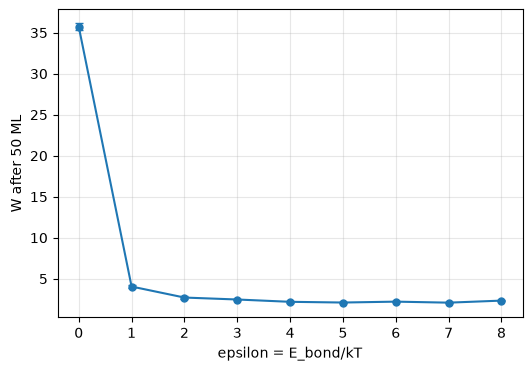

,epsilon,hops_per_landing,roughness,roughness_sem
0,0.0,100,35.726,0.392
1,1.0,100,4.051,0.176
2,2.0,100,2.710,0.166
3,3.0,100,2.471,0.120
4,4.0,100,2.190,0.123
5,5.0,100,2.103,0.118
6,6.0,100,2.211,0.084
7,7.0,100,2.088,0.086
8,8.0,100,2.337,0.099


In [3]:
eps_df = th.sweep_epsilon(base, np.linspace(0, 8, 9), hops=100)
plot_sweep(eps_df, "epsilon", "roughness", "roughness_sem", xlabel="epsilon = E_bond/kT", ylabel="W after 50 ML"); plt.show()
eps_df.round(3)

At **epsilon = 0** nothing holds an atom in place. Atoms hop uphill as readily as downhill, so mass random-walks between columns and the surface becomes very rough (W ≈ 36). Even weak bonding (epsilon = 1) is enough to change this: atoms that reach a site with neighbours tend to stay, which fills dips and smooths the film (W ≈ 4). Above epsilon ≈ 4, W levels off at about 2. There is a slight rise at epsilon = 8, where even singly-bonded atoms almost never move.

## 2. Real units: what temperature does

In [4]:
for T in (250, 300, 350, 400, 450):
    e, h = thermal_parameters(T, base.e_bond, base.e_diff, base.flux)
    print(f"T = {T} K   epsilon = {e:5.2f}   hops per landing = {h:10.3g}")

T = 250 K   epsilon =  9.28   hops per landing =   0.000746
T = 300 K   epsilon =  7.74   hops per landing =      0.364
T = 350 K   epsilon =  6.63   hops per landing =       30.2
T = 400 K   epsilon =  5.80   hops per landing =        833
T = 450 K   epsilon =  5.16   hops per landing =      1e+04


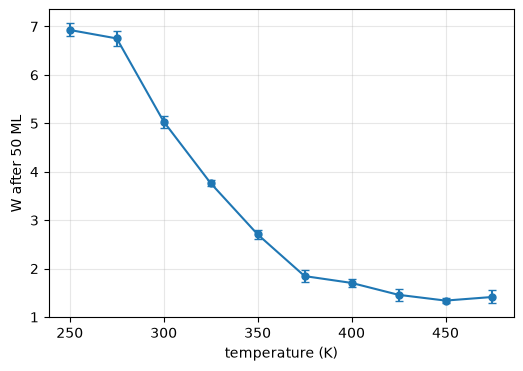

,temperature,flux,epsilon,hops_per_landing,roughness,roughness_sem
0,250.0,1.0,9.284,0.001,6.928,0.134
1,275.0,1.0,8.440,0.022,6.754,0.153
2,300.0,1.0,7.736,0.364,5.036,0.122
3,325.0,1.0,7.141,3.930,3.764,0.065
4,350.0,1.0,6.631,30.235,2.707,0.093
5,375.0,1.0,6.189,177.204,1.845,0.129
6,400.0,1.0,5.802,832.614,1.704,0.089
7,425.0,1.0,5.461,3261.059,1.458,0.123
8,450.0,1.0,5.158,10000.000,1.340,0.059
9,475.0,1.0,4.886,10000.000,1.414,0.135


In [5]:
t_df = th.sweep_temperature(base, np.linspace(250, 475, 10))
plot_sweep(t_df, "temperature", "roughness", "roughness_sem", xlabel="temperature (K)", ylabel="W after 50 ML"); plt.show()
t_df.round(3)

## 3. Real units: what deposition rate does (T = 375 K)

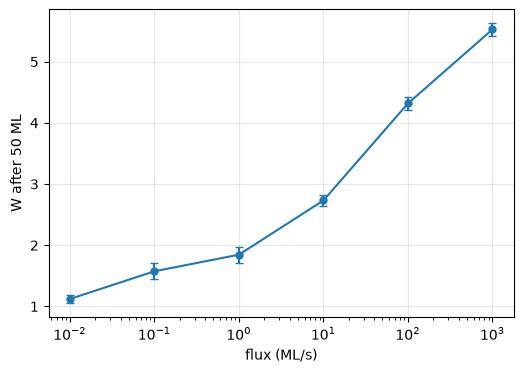

,temperature,flux,epsilon,hops_per_landing,roughness,roughness_sem
0,375,0.01,6.189,10000.000,1.121,0.065
1,375,0.10,6.189,1772.039,1.574,0.133
2,375,1.00,6.189,177.204,1.845,0.129
3,375,10.00,6.189,17.720,2.731,0.097
4,375,100.00,6.189,1.772,4.316,0.109
5,375,1000.00,6.189,0.177,5.527,0.104


In [6]:
f_df = th.sweep_flux(th.ThermalSettings(**{**asdict(base), "temperature": 375}), [0.01, 0.1, 1, 10, 100, 1000])
plot_sweep(f_df, "flux", "roughness", "roughness_sem", logx=True, xlabel="flux (ML/s)", ylabel="W after 50 ML"); plt.show()
f_df.round(3)

## 4. Watch a cold and a hot film grow

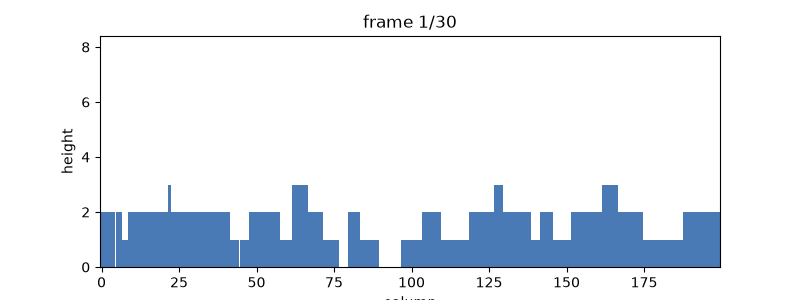

In [7]:
from IPython.display import Image
from thin_film.plotting import animate_profiles, gif_bytes
def frames(T, n=30):
    e, h = thermal_parameters(T, base.e_bond, base.e_diff, base.flux)
    hts = np.zeros(200, np.int64); out = []
    for k in range(n):
        th.thermal_grow(hts, 200 * 50 // n, e, h, k); out.append(hts - hts.min())
    return out
anim = animate_profiles(frames(425)); plt.close()
Image(data=gif_bytes(anim))

## Takeaways
* Roughness falls by about 5x between 250 K and 450 K, because more hops let atoms find well-bonded sites.
* Faster deposition gives a rougher film at a fixed temperature, because new atoms bury the old ones before they can settle.
* Temperature and rate matter only through the ratio of diffusion to arrival. This is why fabs trade substrate heating against throughput.